# Analyzing IT Job Market and Predicting Job Readiness
### Thesis notebook : step by step Implemetation from data loading to Model Development.
How to run : upload `finland_it_jobs_FINAL_ML_READY.csv` to the colab file panel, then run the cell top to bottm.(`Runtime > Run all`)

**What the model predicts :** the data contains job posting only, there is no readiness lable. the model therfore predicts the **role family** for a set of skills . the **rediness score** is a separete defined metric . the demand weighted share of the target **role family's** topskill that a person has .

## Step 1 : import Libraries
- **pandas** : Handling Data
- **numpy** : numerical computation / array maniplation
- **matplotlib, seaborn** : graphs and plotting
- **scikit-learn** : Building machine learning models and evaluation


In [150]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

pd.set_option('display.max_colwidth', 80)
sns.set_theme(style='whitegrid')

## Step 2 : Data Loading
`pd.read_csv()` Load the raw datasets from a CSV File into a DataFrame.

`.shape` = (rows, columns).

`df.head()` (First 5 rwos and columns show).




In [151]:
df = pd.read_csv('/content/finland_it_jobs_FINAL_ML_READY.csv')
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (829, 8)


,Job_Title,Company,Location,Date_Posted,Skills_Domain,Role_Category,Salary_Info,Source
0,Python Backend Developer,Congrid (SmartCraft Group),Remote Finland,NaN,"SQL, PostgreSQL, RESTful APIs, Docker, AWS, CI/CD, React/TypeScript",Backend Development,Not specified,Glassdoor
1,IAM Systems Administrator,Not specified,Finland,NaN,"IAM products, Python, SQL, Linux, Golang, Microsoft Azure, Swedish skills",Cybersecurity,Not specified,itjobs.ai
2,Doctoral Researcher - Cell Biology,Not specified,Finland,NaN,"Python programming, cell culture, molecular biology",AI/ML,Not specified,itjobs.ai
3,Python Software Developer (Robotics),Not specified,Joensuu,NaN,"TensorFlow, Machine Learning, Linux, Deep Learning, Robotics, SLAM, Arduino,...",AI/ML,Not specified,itjobs.ai
4,Test Automation Engineer (GUI/API/DB),Not specified,Finland,NaN,"API, Jenkins, SQL, Python, Linux, CI/CD, XML, Unix, Debugging, Robot Framewo...",QA/Testing,Not specified,itjobs.ai


## Step 3: Understanding the Data  (info aur missing values)

**Guide to Data types (dtype)**

In [152]:
df.dtypes

,0
Job_Title,object
Company,object
Location,object
Date_Posted,object
Skills_Domain,object
Role_Category,object
Salary_Info,object
Source,object


## Step 4: Handling Missing values


In [153]:
df.isnull().sum()

,0
Job_Title,0
Company,0
Location,0
Date_Posted,775
Skills_Domain,0
Role_Category,0
Salary_Info,549
Source,1


In [154]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 829 entries, 0 to 828
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Job_Title      829 non-null    object
 1   Company        829 non-null    object
 2   Location       829 non-null    object
 3   Date_Posted    54 non-null     object
 4   Skills_Domain  829 non-null    object
 5   Role_Category  829 non-null    object
 6   Salary_Info    280 non-null    object
 7   Source         828 non-null    object
dtypes: object(8)
memory usage: 51.9+ KB


# 1) Source: only 1 raw is missing -> impute with Unknown

In [155]:
df.Source.isnull().sum()

np.int64(1)

In [156]:
df['Source'] = df['Source'].fillna('unknown')

In [157]:
df.Source.isnull().sum()

np.int64(0)

# 2) (Salary_Info) 'Not specified' not an actual value, treat as missing values -> Replaced with NaN

In [158]:
df.Salary_Info.isnull().sum()

np.int64(549)

In [159]:
df.Salary_Info.head()

,Salary_Info
0,Not specified
1,Not specified
2,Not specified
3,Not specified
4,Not specified


In [160]:
df.Salary_Info.tail()

,Salary_Info
824,NaN
825,NaN
826,NaN
827,NaN
828,NaN


In [161]:
df.Company.isnull().sum()

np.int64(0)

In [162]:
df.Company.head()

,Company
0,Congrid (SmartCraft Group)
1,Not specified
2,Not specified
3,Not specified
4,Not specified


In [163]:
df.Company.tail()

,Company
824,Not specified
825,Oura
826,Resourceful Talent Group
827,Not specified
828,Not specified


In [164]:
df['Salary_Info'] = df['Salary_Info'].replace('Not specified', np.nan)
df['Company'] = df['Company'].replace('Not specified', np.nan)

print(df.isnull().sum())

Job_Title          0
Company          540
Location           0
Date_Posted      775
Skills_Domain      0
Role_Category      0
Salary_Info      810
Source             0
dtype: int64


In [165]:
df.Company.tail()

,Company
824,NaN
825,Oura
826,Resourceful Talent Group
827,NaN
828,NaN


In [166]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 829 entries, 0 to 828
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Job_Title      829 non-null    object
 1   Company        289 non-null    object
 2   Location       829 non-null    object
 3   Date_Posted    54 non-null     object
 4   Skills_Domain  829 non-null    object
 5   Role_Category  829 non-null    object
 6   Salary_Info    19 non-null     object
 7   Source         829 non-null    object
dtypes: object(8)
memory usage: 51.9+ KB


In [167]:
df['Date_Posted'].value_counts()

,count
Date_Posted,
2.9.2026,8
Not specified,8
August 28,4
August 24,4
8.9.2026,3
July 24,3
July 12,3
September 1,2
September 3,1


## Step 5 : Convert Datas
# Date_Posted : Has two date formats "25.08.2026" and "July 12" Each format is parsed seprately . (missing years)

In [168]:
d = df['Date_Posted'].astype('string')
date_a = pd.to_datetime(d, format='%d.%m.%Y', errors='coerce')
date_b = pd.to_datetime(d + ' 2026', format='%B %d %Y', errors='coerce')   # saal 2026 maan liya
df['Date_Posted'] = date_a.fillna(date_b)

print("Dtype:", df['Date_Posted'].dtype)
print("Dates mili:", df['Date_Posted'].notna().sum(), "of", len(df))
print(df['Date_Posted'].dropna().sort_values().head(3).tolist())

Dtype: datetime64[ns]
Dates mili: 44 of 829
[Timestamp('2026-06-15 00:00:00'), Timestamp('2026-07-01 00:00:00'), Timestamp('2026-07-12 00:00:00')]


## Step 6 : Identifying and removing Duplicates

In [169]:
print(df.duplicated().sum())
print("Title + Company + Location Same :", df.duplicated(subset=['Job_Title','Company','Location']).sum())

0
Title + Company + Location Same : 0


In [170]:
df

,Job_Title,Company,Location,Date_Posted,Skills_Domain,Role_Category,Salary_Info,Source
0,Python Backend Developer,Congrid (SmartCraft Group),Remote Finland,NaT,"SQL, PostgreSQL, RESTful APIs, Docker, AWS, CI/CD, React/TypeScript",Backend Development,NaN,Glassdoor
1,IAM Systems Administrator,NaN,Finland,NaT,"IAM products, Python, SQL, Linux, Golang, Microsoft Azure, Swedish skills",Cybersecurity,NaN,itjobs.ai
2,Doctoral Researcher - Cell Biology,NaN,Finland,NaT,"Python programming, cell culture, molecular biology",AI/ML,NaN,itjobs.ai
3,Python Software Developer (Robotics),NaN,Joensuu,NaT,"TensorFlow, Machine Learning, Linux, Deep Learning, Robotics, SLAM, Arduino,...",AI/ML,NaN,itjobs.ai
4,Test Automation Engineer (GUI/API/DB),NaN,Finland,NaT,"API, Jenkins, SQL, Python, Linux, CI/CD, XML, Unix, Debugging, Robot Framewo...",QA/Testing,NaN,itjobs.ai
...,...,...,...,...,...,...,...,...
824,Master's Level IT/CS Trainee,NaN,Finland,NaT,"Information technology, computer science, accounting intersection",Software Development,NaN,Glassdoor
825,Wearable Tech Software Engineer,Oura,Oulu,NaT,"Wearable technology software, equal opportunity workplace",Software Development,NaN,Glassdoor
826,Product Manager (CTO Collaboration),Resourceful Talent Group,Finland,NaT,"Product requirements, business idea translation, stakeholder collaboration",Product Management,NaN,Glassdoor
827,QA Automation Apprentice (Microsoft Partnership),NaN,Finland,NaT,"Cloud Computing, Cyber Security, Data, Analytics, AI, DevOps apprenticeship ...",QA/Testing,NaN,Wikipedia/QA company


In [171]:
df['Job_Title'].value_counts().sort_values(ascending=False)

,count
Job_Title,
Game Developer,8
Full Stack Developer,3
Senior Data Analyst,2
Senior Software Developer,2
Senior Software Engineer,2
...,...
Senior Back End Developer (Node.js),1
Engineering Manager,1
Java Developer (banking sector),1


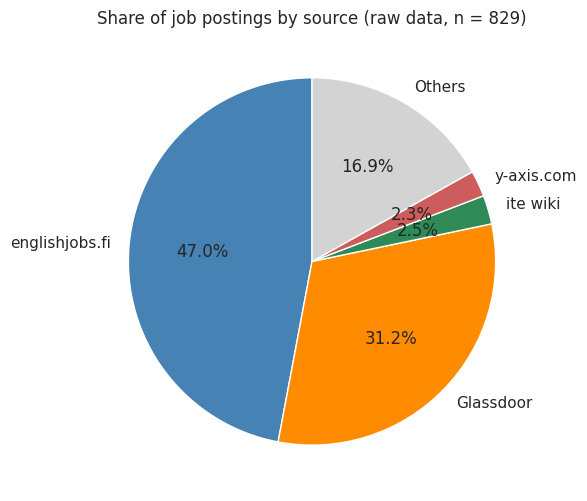

englishjobs.fi    390
Glassdoor         259
ite wiki           21
y-axis.com         19
Others            140
dtype: int64


In [172]:
src = df['Source'].fillna('Unknown').value_counts()      # raw data
main = src.head(4)                                      # top 4 sources
pie_data = pd.concat([main, pd.Series({'Others': src.iloc[4:].sum()})])

plt.figure(figsize=(6, 6))
plt.pie(pie_data.values, labels=pie_data.index, autopct='%1.1f%%', startangle=90,
        colors=['steelblue', 'darkorange', 'seagreen', 'indianred', 'lightgray'])
plt.title(f'Share of job postings by source (raw data, n = {len(df)})')
plt.tight_layout()
plt.show()
print(pie_data)

In [173]:
df['Location'].value_counts().sort_values(ascending=False)

,count
Location,
Finland,583
Helsinki,125
Espoo,21
Finland (Remote),18
Tampere,14
Turku,9
Oulu,5
Not specified,5
Vantaa,4


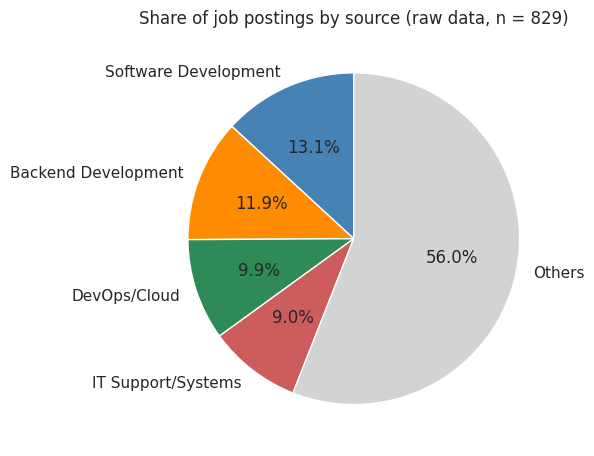

Software Development    109
Backend Development      99
DevOps/Cloud             82
IT Support/Systems       75
Others                  464
dtype: int64


In [174]:
src = df['Role_Category'].fillna('Unknown').value_counts()      # raw data
main = src.head(4)                                      # top 4 sources
pie_data = pd.concat([main, pd.Series({'Others': src.iloc[4:].sum()})])

plt.figure(figsize=(6, 6))
plt.pie(pie_data.values, labels=pie_data.index, autopct='%1.1f%%', startangle=90,
        colors=['steelblue', 'darkorange', 'seagreen', 'indianred', 'lightgray'])
plt.title(f'Share of job postings by source (raw data, n = {len(df)})')
plt.tight_layout()
plt.show()
print(pie_data)

Role_Category             AI/ML  Backend Development  Blockchain  \
Main_Location                                                      
Lappeenranta                  0                    0           0   
Jyväskylä                     0                    0           0   
Kuopio                        0                    0           0   
Joensuu                       3                    0           0   
Vaasa                         0                    0           0   
Vantaa                        0                    0           0   
Oulu                          1                    1           0   
Turku                         0                    2           0   
Tampere                       0                    0           0   
Remote                        2                    2           1   
Espoo                         1                    7           0   
Helsinki                      5                   22           0   
Finland (city not given)     44                 

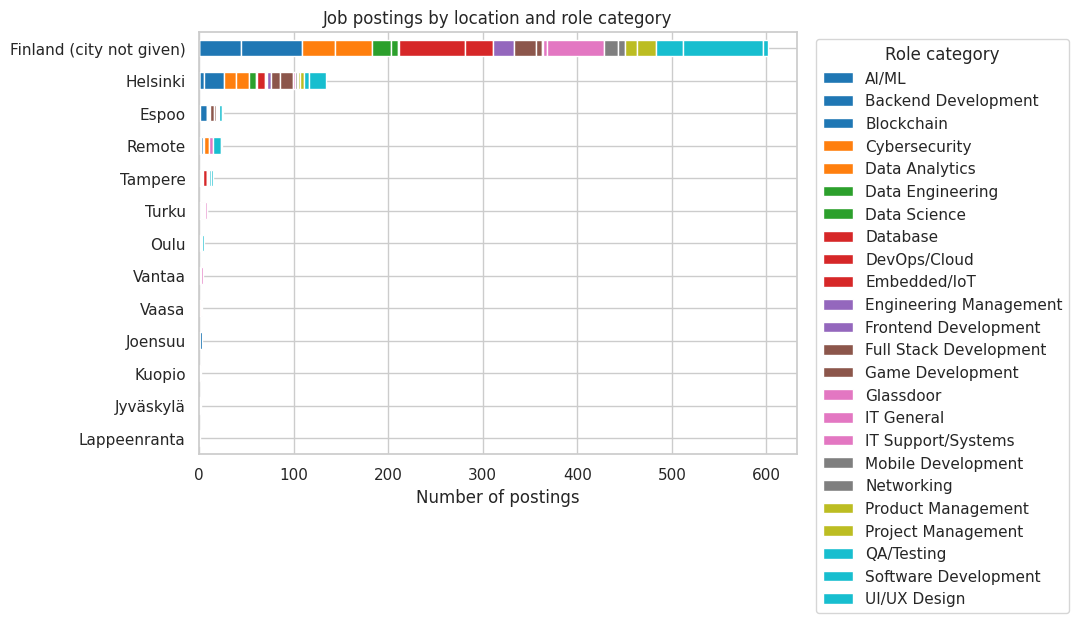

In [175]:
cities = ['Helsinki', 'Espoo', 'Vantaa', 'Tampere', 'Turku', 'Oulu', 'Jyväskylä', 'Kuopio',
          'Lahti', 'Vaasa', 'Joensuu', 'Lappeenranta', 'Kouvola', 'Pori']

def main_location(text):
    t = str(text)
    if 'remote' in t.lower():
        return 'Remote'
    for c in cities:
        if c.lower() in t.lower():
            return c
    return 'Finland (city not given)'

df['Main_Location'] = df['Location'].apply(main_location)

# Fixed: Changed 'Role_Family' to 'Role_Category'
ct = pd.crosstab(df['Main_Location'], df['Role_Category'])
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=True).index]
print(ct)

ct.plot(kind='barh', stacked=True, figsize=(11, 6), colormap='tab10')
plt.title('Job postings by location and role category')
plt.xlabel('Number of postings')
plt.ylabel('')
plt.legend(title='Role category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Location-wise Job Availability Percentage
Let's calculate and plot the percentage share of job postings available across different locations in Finland.

Main_Location
City not given    72.6
Helsinki          16.2
Espoo              3.0
Remote             2.9
Tampere            1.8
Turku              1.1
Oulu               0.6
Vantaa             0.5
Joensuu            0.4
Vaasa              0.4
Kuopio             0.2
Jyväskylä          0.2
Lappeenranta       0.1
Name: proportion, dtype: float64


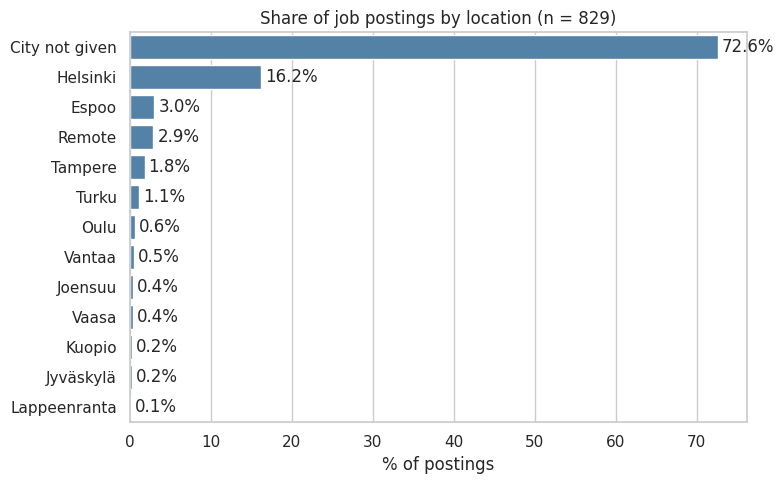

City wali rows: 227 of 829


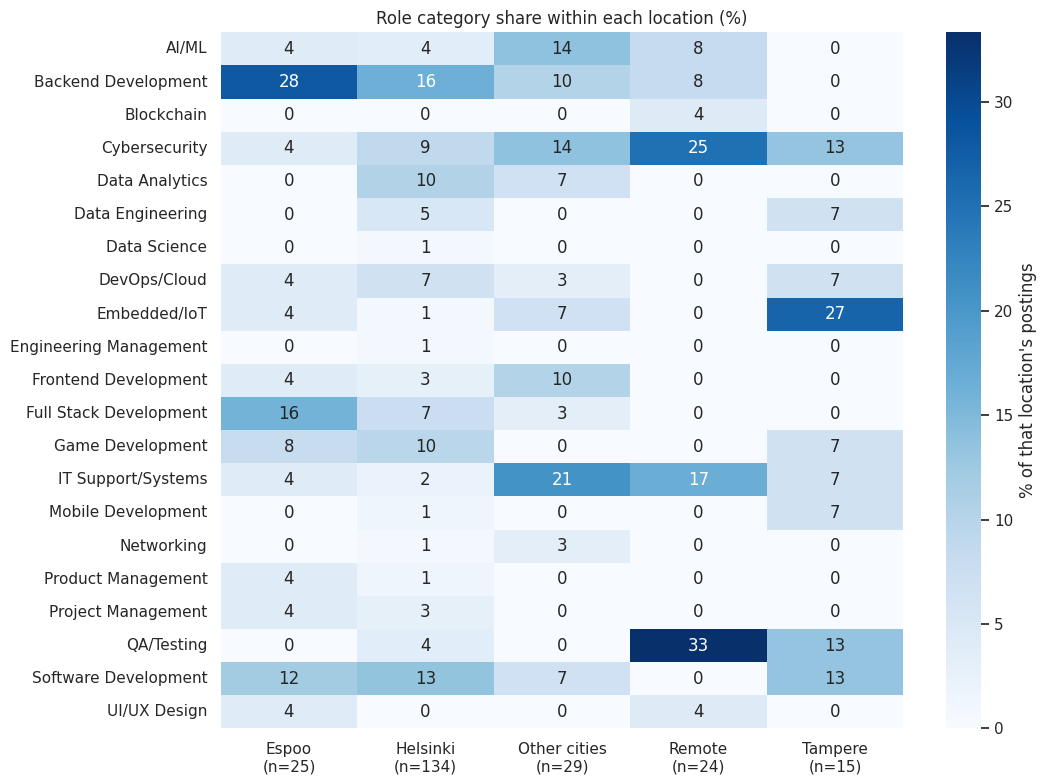

In [176]:
# Step A: Extract primary city from Location
cities = ['Helsinki', 'Espoo', 'Vantaa', 'Tampere', 'Turku', 'Oulu', 'Jyväskylä', 'Kuopio',
          'Lahti', 'Vaasa', 'Joensuu', 'Lappeenranta', 'Kouvola', 'Pori']

def main_location(text):
    t = str(text).lower()
    if 'remote' in t:
        return 'Remote'
    for c in cities:
        if c.lower() in t:
            return c
    return 'City not given'

df['Main_Location'] = df['Location'].apply(main_location)

# Percentage distribution of jobs by location
loc_pct = (df['Main_Location'].value_counts(normalize=True) * 100).round(1)
print(loc_pct)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=loc_pct.values, y=loc_pct.index, color='steelblue')
for i, v in enumerate(loc_pct.values):
    ax.text(v + 0.5, i, f"{v}%", va='center')
plt.title(f'Share of job postings by location (n = {len(df)})')
plt.xlabel('% of postings')
plt.ylabel('')
plt.tight_layout()
plt.show()

# Graph 2: Location vs Role_Category (Percentage breakdown each location)
known = df[df['Main_Location'] != 'City not given'].copy()
print("City wali rows:", len(known), "of", len(df))

counts = known['Main_Location'].value_counts()
small = counts[counts < 10].index                      # 10 job postings cities
known['Main_Location'] = known['Main_Location'].replace({c: 'Other cities' for c in small})

ct = pd.crosstab(known['Role_Category'].astype(str), known['Main_Location'], normalize='columns') * 100
n = known['Main_Location'].value_counts()
ct.columns = [f"{c}\n(n={n[c]})" for c in ct.columns]

plt.figure(figsize=(11, 8))
sns.heatmap(ct, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': "% of that location's postings"})
plt.title('Role category share within each location (%)')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

## Step 7 : Text cleaning and preprocessing
Removes whitespace from strings.

In [177]:
text_cols = ['Job_Title', 'Company', 'Location', 'Skills_Domain', 'Role_Category', 'Source']
for col in text_cols:
    df[col] = df[col].str.strip()

df['Skills_Domain'] = df['Skills_Domain'].str.replace(r'\s+', ' ', regex=True)

## Step 8 :  Remove all records that are not real job postings .
Some records were summeries  (Salry benchmarks, aggregate counts, sector level information ) rather then individual posting . they all remove befor anay

In [178]:
not_real_sources = ['y-axis.com', 'gameindustrycareerguide.com', 'shecodes.io', 'erieri.com',
                    'payscale.com', 'Wikipedia/QA company', 'Wikipedia/telecom report',
                    'infofinland.fi', 'itjobs.ai']

is_aggregate = df['Source'].str.contains('aggregate', case=False, na=False)
is_benchmark = df['Job_Title'].str.contains(r'benchmark|market size|average salary|\(average\)', case=False, na=False)
is_bad_source = df['Source'].isin(not_real_sources)

remove = is_aggregate | is_benchmark | is_bad_source
print("Rows removed:", remove.sum())
df = df[~remove].reset_index(drop=True)
print("Remaining rows:", len(df))

Rows removed: 59
Remaining rows: 770


## Step 9: Create Role families :
`Role_Category` has more then 18 labels , some with very few rows . grouped into 8 role familes so that each class has enough examples . lable that don't fit any family are droped. the grouping is a reserch decision  and can be edited in ` family_map `

In [179]:
# Group Role_Category into 8 larger groups (role families).
# The dataset is small, so very small categories would not give the model enough examples to learn from.
# This mapping is a research decision and can be changed.

family_map = {
    'Software Development':   'Software Development',
    'Backend Development':    'Software Development',
    'Full Stack Development': 'Software Development',
    'Frontend Development':   'Software Development',
    'Mobile Development':     'Software Development',
    'Game Development':       'Software Development',
    'DevOps/Cloud':           'Cloud & DevOps',
    'Cybersecurity':          'Cybersecurity',
    'QA/Testing':             'QA & Testing',
    'IT Support/Systems':     'IT Support & Networking',
    'Networking':             'IT Support & Networking',
    'Embedded/IoT':           'Embedded & IoT',
    'AI/ML':                  'Data & AI',
    'Data Science':           'Data & AI',
    'Data Analytics':         'Data & AI',
    'Data Engineering':       'Data & AI',
    'Project Management':     'Product & Project Management',
    'Product Management':     'Product & Project Management',
}
df['Role_Family'] = df['Role_Category'].map(family_map)

print("will be dropped:")
print(df[df['Role_Family'].isna()]['Role_Category'].value_counts())

df = df.dropna(subset=['Role_Family']).reset_index(drop=True)
df['Role_Category'] = df['Role_Category'].astype('category')
df['Role_Family'] = df['Role_Family'].astype('category')
df['Source'] = df['Source'].astype('category')
print()
print(df['Role_Family'].value_counts())

will be dropped:
Role_Category
UI/UX Design              6
Glassdoor                 1
Blockchain                1
Engineering Management    1
Database                  1
Name: count, dtype: int64

Role_Family
Software Development            292
Data & AI                       141
Cloud & DevOps                   80
IT Support & Networking          73
Cybersecurity                    57
QA & Testing                     40
Product & Project Management     39
Embedded & IoT                   38
Name: count, dtype: int64


In [180]:
df['Role_Family'].value_counts().sum()

np.int64(760)

## Step 10: Skill extraction (NLP, dictionary matching)

Skills are extracted with dictionary based matching :

1. Skill Dictionary : skill dictionary map each skill name to a pattern . (Regular expression )
2. Multi-Hot Encoding : each posting gets 0/1 columans per skill .
3. Frequency Pruning : Skills found in fewer then 5 posting are dropped .
4. Zero-Skill Exclusion : Posting with no detected skill are romoved , because  model cannot learn from tem .


In [181]:
#  Skill dictionary: skill name -> pattern (regular expression) used to find it in the text .

SKILL_PATTERNS = {
    # programming languages
    'python': r'python', 'java': r'(?<![a-z])java(?!script)', 'javascript': r'javascript|(?<![a-z.])js(?![a-z])',
    'typescript': r'typescript', 'c#': r'c#', 'c++': r'c\+\+', 'rust': r'(?<![a-z])rust(?![a-z])',
    'kotlin': r'kotlin', 'swift': r'(?<![a-z])swift(?![a-z])', 'php': r'(?<![a-z])php(?![a-z])',
    'scala': r'(?<![a-z])scala(?![a-z])', 'matlab': r'matlab|simulink', '.net': r'\.net|dotnet',
    # web
    'react': r'react(?![a-z])|reactjs', 'angular': r'angular', 'vue': r'vue(?![a-z])', 'node.js': r'node\.?js',
    'next.js': r'next\.?js', 'html': r'html', 'css': r'(?<![a-z])css(?![a-z])', 'django': r'django',
    'flask': r'flask', 'fastapi': r'fastapi', 'laravel': r'laravel',
    'api': r'(?<![a-z])apis?(?![a-z])|restful|rest api', 'microservices': r'microservice',
    # data
    'sql': r'(?<![a-z])sql', 'postgresql': r'postgres', 'mysql': r'mysql', 'mongodb': r'mongo',
    'snowflake': r'snowflake', 'databricks': r'databricks', 'bigquery': r'bigquery', 'spark': r'(?<![a-z])spark',
    'kafka': r'kafka', 'airflow': r'airflow', 'power bi': r'power ?bi', 'tableau': r'tableau',
    'excel': r'excel(?![a-z])', 'etl': r'(?<![a-z])etl(?![a-z])', 'data warehouse': r'data warehous',
    'pandas': r'pandas', 'numpy': r'numpy', 'data analysis': r'data analy|analytics|business intelligence|dashboard',
    'statistics': r'statistic',
    # AI / ML
    'machine learning': r'machine learning|(?<![a-z])ml(?![a-z])', 'deep learning': r'deep learning',
    'tensorflow': r'tensorflow', 'pytorch': r'pytorch', 'scikit-learn': r'scikit', 'nlp': r'(?<![a-z])nlp(?![a-z])|natural language',
    'computer vision': r'computer vision', 'llm': r'(?<![a-z])llms?(?![a-z])|large language',
    'generative ai': r'generative ai|genai', 'mlops': r'mlops', 'ai': r'(?<![a-z])ai(?![a-z])',
    # cloud / devops
    'aws': r'(?<![a-z])aws(?![a-z])|amazon', 'azure': r'azure', 'gcp': r'gcp|google cloud', 'cloud': r'cloud',
    'kubernetes': r'kubernetes|k8s', 'docker': r'docker|containeri', 'terraform': r'terraform', 'ansible': r'ansible',
    'jenkins': r'jenkins', 'ci/cd': r'ci/cd|ci-cd|cicd', 'git': r'(?<![a-z])git(?![a-z])|github|gitlab',
    'linux': r'linux', 'devops': r'devops|devsecops', 'infrastructure as code': r'infrastructure as code|(?<![a-z])iac(?![a-z])',
    'monitoring': r'prometheus|grafana|datadog|observability|monitoring', 'openstack': r'openstack',
    # security
    'security': r'security', 'owasp': r'owasp', 'nist': r'nist', 'siem': r'siem',
    'penetration testing': r'penetration|pentest|red team|ethical hack',
    'iam': r'(?<![a-z])iam(?![a-z])|identity (?:and access|governance|management)',
    'soc': r'(?<![a-z])soc(?![a-z])|security operations', 'cryptography': r'cryptograph|(?<![a-z])pki(?![a-z])|ipsec',
    'compliance': r'compliance|gdpr|iso 27001',
    # testing
    'test automation': r'test automation|automated test|test-automation', 'selenium': r'selenium', 'playwright': r'playwright',
    'robot framework': r'robot framework', 'testing / qa': r'testing|(?<![a-z])qa(?![a-z])|quality assurance',
    # other
    'agile': r'agile|scrum|kanban', 'jira': r'jira', 'sap': r'(?<![a-z])sap(?![a-z])', 'salesforce': r'salesforce',
    'odoo': r'odoo', 'erp': r'(?<![a-z])erp(?![a-z])', 'embedded': r'embedded|firmware|rtos',
    'iot': r'(?<![a-z])iot(?![a-z])', 'ros': r'(?<![a-z])ros2?(?![a-z])', 'unity': r'unity', 'unreal': r'unreal',
    'ux/ui design': r'(?<![a-z])ux(?![a-z])|(?<![a-z])ui(?![a-z])|figma|interaction design',
    'networking': r'network', 'android': r'android', 'ios': r'(?<![a-z])ios(?![a-z])', 'flutter': r'flutter',
    'project management': r'project manage|program manage|project manager',
    'product management': r'product manage|product owner|roadmap', 'saas': r'saas',
}

skills_text = df['Skills_Domain'].fillna('')
skills_lower = skills_text.str.lower()

skill_cols = {name: skills_lower.str.contains(pat, regex=True) for name, pat in SKILL_PATTERNS.items()}
# Separate rule for the "Go" language (capital G, otherwise "go-to-market" would match too)
skill_cols['go'] = skills_text.str.contains(r'(?<![A-Za-z0-9])Go(?![A-Za-z0-9\-])|golang', regex=True)

skill_df = pd.DataFrame(skill_cols).astype(int)

# Drop skills that appear in fewer than 5 postings
keep = skill_df.columns[skill_df.sum() >= 5]
skill_df = skill_df[keep]

print("Skills in dictionary:", len(SKILL_PATTERNS) + 1, "| Retained (5+ occurrences):", skill_df.shape[1])
print("Mean skills per posting:", round(skill_df.sum(axis=1).mean(), 2))
print("Zero skill records excluded:", (skill_df.sum(axis=1) == 0).sum())

Skills in dictionary: 106 | Retained (5+ occurrences): 57
Mean skills per posting: 1.2
Zero skill records excluded: 294


In [182]:
has_skill = skill_df.sum(axis=1) > 0
df = df[has_skill].reset_index(drop=True)
skill_df = skill_df[has_skill].reset_index(drop=True)
print("Final dataset:", df.shape, "| skill matrix:", skill_df.shape)
print(skill_df.dtypes.value_counts())

Final dataset: (466, 10) | skill matrix: (466, 57)
int64    57
Name: count, dtype: int64


Postings: 466
Skills detected (5+ postings): 57
Average skills per posting: 1.95

Top 10 skills (% of postings):
cloud            13.5
ai               12.7
security         10.5
react             7.9
python            7.5
azure             6.9
testing / qa      6.7
typescript        5.4
aws               5.4
data analysis     5.2
dtype: float64


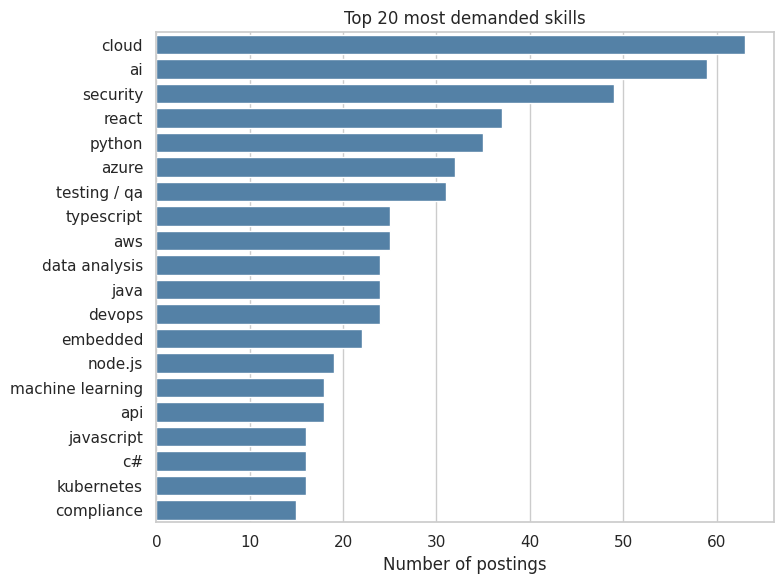

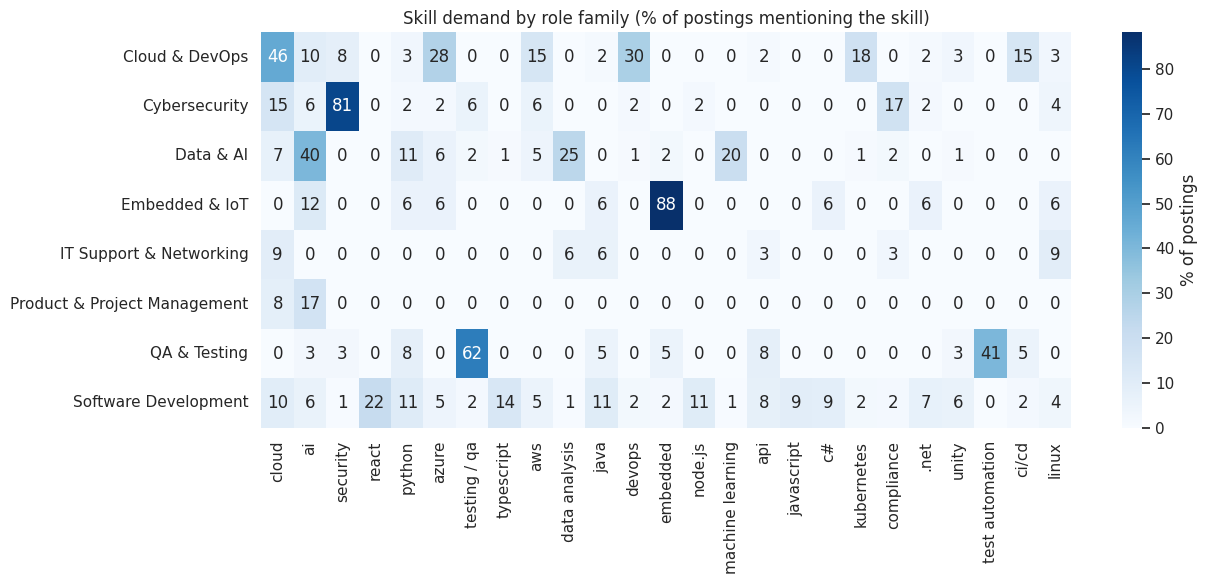

In [183]:
print("Postings:", len(df))
print("Skills detected (5+ postings):", skill_df.shape[1])
print("Average skills per posting:", round(skill_df.sum(axis=1).mean(), 2))

top = skill_df.sum().sort_values(ascending=False).head(20)
print("\nTop 10 skills (% of postings):")
print((top / len(df) * 100).round(1).head(10))

# Figure 1: top 20 skills
plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, color='steelblue')
plt.title('Top 20 most demanded skills')
plt.xlabel('Number of postings')
plt.ylabel('')
plt.tight_layout()
plt.savefig('figure1_top_skills.png', dpi=300)
plt.show()

# Figure 2: role family vs skills heatmap
share = skill_df.groupby(df['Role_Family'], observed=True).mean() * 100
top_skills = skill_df.sum().sort_values(ascending=False).head(25).index

plt.figure(figsize=(13, 6))
sns.heatmap(share[top_skills], annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% of postings'})
plt.title('Skill demand by role family (% of postings mentioning the skill)')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.savefig('figure2_role_heatmap.png', dpi=300)
plt.show()

## Step 11: E.D.A. Data Visualization (Exploratry analysis)
- **Bar Chart** : The most demanded skills .
- **Heatmap Matrix** : Share of posting mentioning each skill , per role family .



cloud               63
ai                  59
security            49
react               37
python              35
azure               32
testing / qa        31
typescript          25
aws                 25
data analysis       24
java                24
devops              24
embedded            22
node.js             19
machine learning    18
api                 18
javascript          16
c#                  16
kubernetes          16
compliance          15
dtype: int64


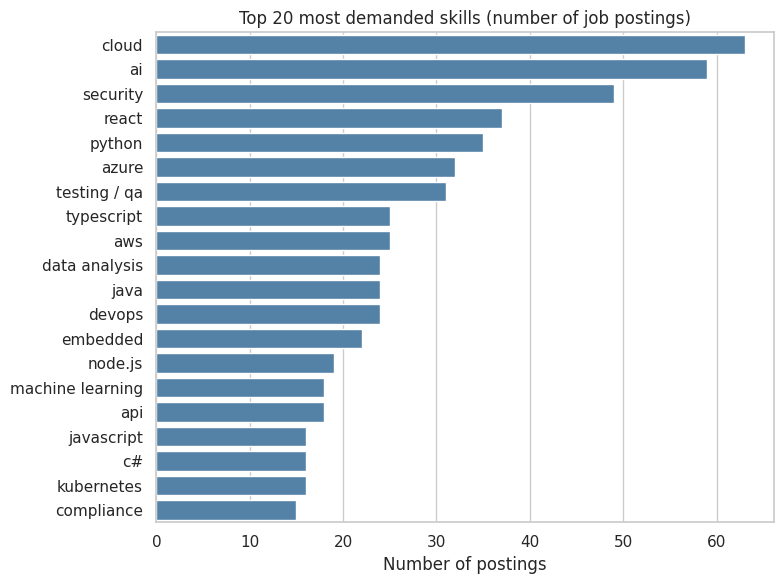

In [184]:
top = skill_df.sum().sort_values(ascending=False).head(20)
print(top)

plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, color='steelblue')
plt.title('Top 20 most demanded skills (number of job postings)')
plt.xlabel('Number of postings')
plt.ylabel('')
plt.tight_layout()
plt.show()

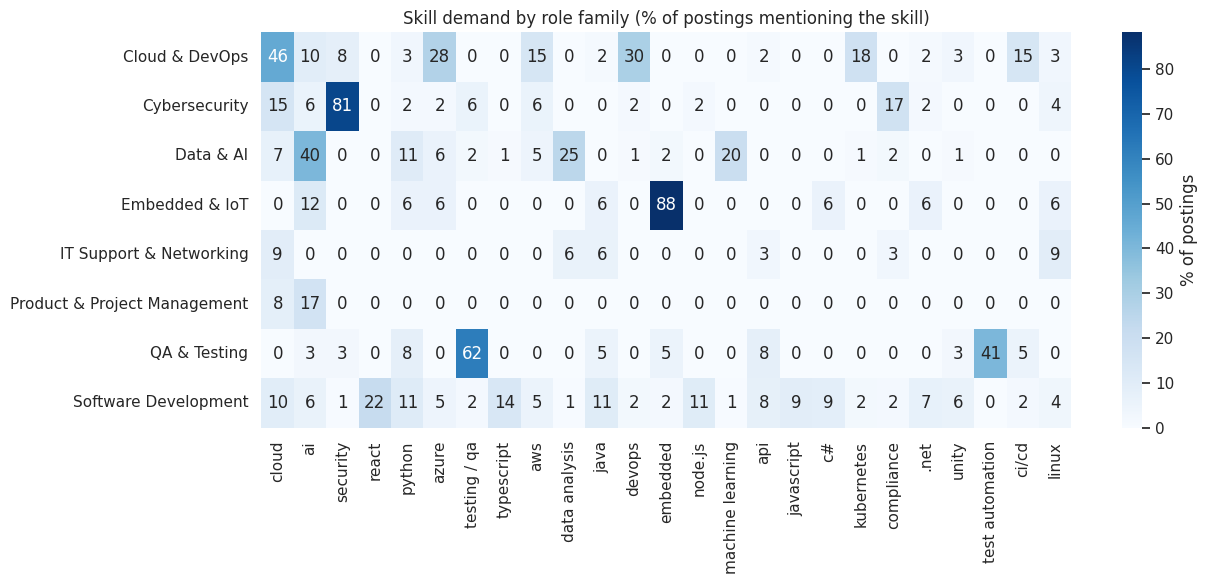

In [185]:
# Share of postings (%) that mention each skill, per role family .
share = skill_df.groupby(df['Role_Family'], observed=True).mean() * 100
top_skills = skill_df.sum().sort_values(ascending=False).head(25).index

plt.figure(figsize=(13, 6))
sns.heatmap(share[top_skills], annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% of postings'})
plt.title('Skill demand by role family (% of postings mentioning the skill)')
plt.xlabel('')
plt.ylabel('')
plt.tight_layout()
plt.show()

In [186]:
df.shape

(466, 10)

## Step 12: Train/test split and model training .
- **Train/test split (80/20)** : 80% Data for training and 20% data for testing  . `stratify=y` preserves class balance across partition, `random_state=42` guarantees reproducibility.
- **Baseline** : Logistic Regression and Random Forest (Always predict the most common class)
- **5-fold cross-validation** : Which is more reliable then a single test set on small dataset .

In [187]:
X = skill_df.values
y = df['Role_Family'].astype(str).values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (372, 57) | Test: (94, 57)


In [188]:
models = {
    'Baseline (most common class)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv_acc = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    results.append({
        'Model': name,
        'Test accuracy': round(accuracy_score(y_test, pred), 3),
        'Test macro-F1': round(f1_score(y_test, pred, average='macro'), 3),
        '5-fold CV accuracy': f"{cv_acc.mean():.3f} +/- {cv_acc.std():.3f}",
    })

pd.DataFrame(results)

,Model,Test accuracy,Test macro-F1,5-fold CV accuracy
0,Baseline (most common class),0.372,0.068,0.367 +/- 0.003
1,Logistic Regression,0.840,0.838,0.768 +/- 0.046
2,Random Forest,0.809,0.845,0.758 +/- 0.043


## Step 13 : Model evaluation .
accuracy , precision , recall and F1 per role family ,plus a confusion matrix .

Note : that words such as **"security"** , **"testing"** , and **"embedded"** describe the role area itself , so high scores for some famillies the data and not only the model .

                              precision    recall  f1-score   support

              Cloud & DevOps       0.55      0.50      0.52        12
               Cybersecurity       1.00      1.00      1.00        11
                   Data & AI       0.76      0.94      0.84        17
              Embedded & IoT       0.75      1.00      0.86         3
     IT Support & Networking       0.83      0.83      0.83         6
Product & Project Management       1.00      1.00      1.00         2
                QA & Testing       1.00      0.88      0.93         8
        Software Development       0.81      0.74      0.78        35

                    accuracy                           0.81        94
                   macro avg       0.84      0.86      0.85        94
                weighted avg       0.81      0.81      0.81        94



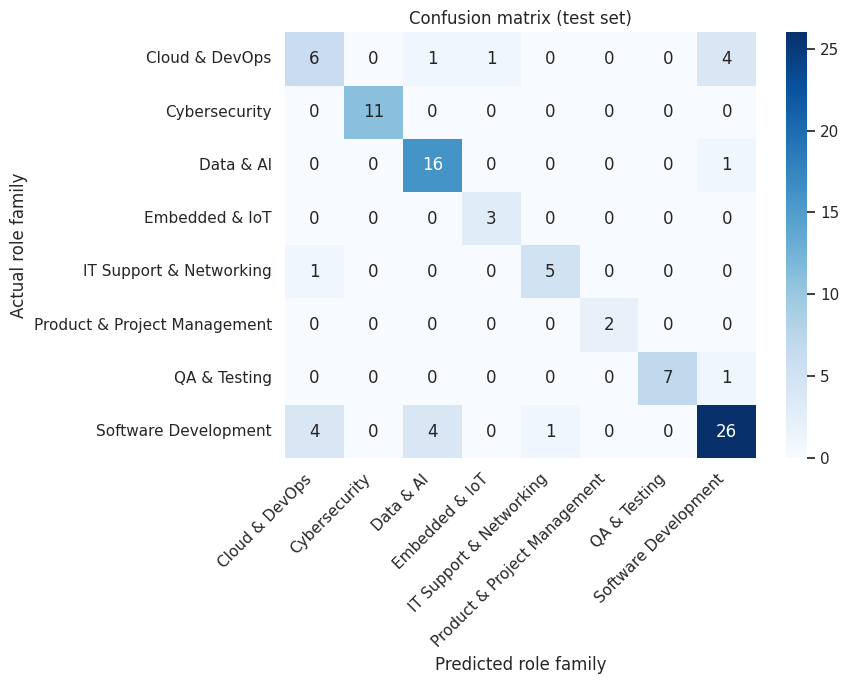

In [189]:
best_model = models['Random Forest']   # use the model that performs better in your results
pred = best_model.predict(X_test)

print(classification_report(y_test, pred, zero_division=0))

labels = sorted(set(y))
cm = confusion_matrix(y_test, pred, labels=labels)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted role family')
plt.ylabel('Actual role family')
plt.title('Confusion matrix (test set)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

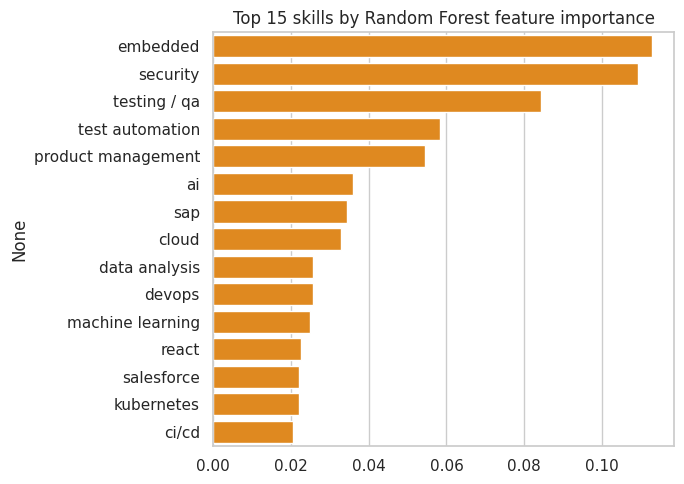

In [190]:
# Skills that matter most for deciding the role family (Random Forest)
imp = pd.Series(models['Random Forest'].feature_importances_, index=skill_df.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(7, 5))
sns.barplot(x=imp.values, y=imp.index, color='darkorange')
plt.title('Top 15 skills by Random Forest feature importance')
plt.tight_layout()
plt.show()

## Step 14 : Readiness score and skill gap .
The Final Model is retrained on data `readiness_report()` returns :
1. **Model**: The role famillies that best match the given skills (model probability) .
2. **Readiness score**: Demand weighted coverage of the target family's top-N skills .
3. **Missing skills**: The missing skills among those top-N skills


In [191]:
# Final model: retrained on all data (evaluation is already done)
final_model = LogisticRegression(max_iter=2000, class_weight='balanced').fit(X, y)

# For each family: share of postings that mention each skill
family_profile = skill_df.groupby(df['Role_Family'], observed=True).mean()

def to_vector(user_skills):
    user = {s.lower().strip() for s in user_skills}
    return np.array([[1 if c in user else 0 for c in skill_df.columns]]), user

def readiness_report(user_skills, target_family, top_n=10):
    vec, user = to_vector(user_skills)
    unknown = [s for s in user if s not in skill_df.columns]

    # 1) Model: which role family these skills match best (probability)
    proba = pd.Series(final_model.predict_proba(vec)[0], index=final_model.classes_).sort_values(ascending=False)

    # 2) Skill coverage: how many of the target role's top-N skills the user has (weighted by demand)
    wanted = family_profile.loc[target_family].sort_values(ascending=False).head(top_n)
    have = [s for s in wanted.index if s in user]
    missing = [s for s in wanted.index if s not in user]
    score = round(100 * wanted[have].sum() / wanted.sum(), 1)

    print(f"Target role family : {target_family}")
    print(f"Readiness score    : {score}%   (demand-weighted coverage of the top {top_n} skills)")
    print(f"Skills jo hain     : {have}")
    print(f"Skills missing  : {missing}")
    if unknown:
        print(f"(Not in skill dictionary: {unknown})")
    print("\nBest-fit role families according to the model:")
    print((proba.head(3) * 100).round(1).astype(str) + ' %')

readiness_report(['python', 'sql', 'machine learning', 'git', 'cloud'], 'Data & AI')

Target role family : Data & AI
Readiness score    : 30.8%   (demand-weighted coverage of the top 10 skills)
Skills jo hain     : ['machine learning', 'python', 'cloud', 'sql']
Skills missing  : ['ai', 'data analysis', 'computer vision', 'llm', 'azure', 'aws']

Best-fit role families according to the model:
Data & AI               82.4 %
Software Development    10.6 %
Cloud & DevOps           3.2 %
dtype: object


In [192]:
# Strong profile: the score should be high
readiness_report(['python', 'sql', 'machine learning', 'ai', 'data analysis', 'llm', 'aws', 'azure'], 'Data & AI')

# Mismatched profile: the score should be low and the best fit should be Software Development
readiness_report(['react', 'javascript', 'css', 'git'], 'Data & AI')

Target role family : Data & AI
Readiness score    : 85.8%   (demand-weighted coverage of the top 10 skills)
Skills jo hain     : ['ai', 'data analysis', 'machine learning', 'python', 'llm', 'azure', 'sql', 'aws']
Skills missing  : ['computer vision', 'cloud']

Best-fit role families according to the model:
Data & AI               100.0 %
Cloud & DevOps            0.0 %
Software Development      0.0 %
dtype: object
Target role family : Data & AI
Readiness score    : 0.0%   (demand-weighted coverage of the top 10 skills)
Skills jo hain     : []
Skills missing  : ['ai', 'data analysis', 'machine learning', 'computer vision', 'python', 'llm', 'cloud', 'azure', 'sql', 'aws']

Best-fit role families according to the model:
Software Development       92.5 %
IT Support & Networking     1.7 %
Data & AI                   1.3 %
dtype: object


In [193]:
# Vectorize a sample user profile and get the probability distribution globally
vec, user = to_vector(['python', 'sql', 'machine learning', 'git', 'cloud'])
proba = pd.Series(final_model.predict_proba(vec)[0], index=final_model.classes_).sort_values(ascending=False)

# Print the top 3 best-fit families
print((proba.head(3) * 100).round(1).astype(str).add(' %').to_string())

Data & AI               82.4 %
Software Development    10.6 %
Cloud & DevOps           3.2 %


In [194]:
print((proba.head(3) * 100).round(1).astype(str).add(' %').to_string())

Data & AI               82.4 %
Software Development    10.6 %
Cloud & DevOps           3.2 %


# Step 15: Files save and output

In [195]:
df.to_csv('finland_it_jobs_CLEANED.csv', index=False)
skill_df.to_csv('finland_it_jobs_SKILL_MATRIX.csv', index=False)
print("Saved: finland_it_jobs_CLEANED.csv, finland_it_jobs_SKILL_MATRIX.csv")

Saved: finland_it_jobs_CLEANED.csv, finland_it_jobs_SKILL_MATRIX.csv
